# Exploratory Data Analysis: Fantasy Football
## CSCI 5502 - Milestone 2

### Objective

This notebook explores historical NFL fantasy football data from
the 2025 season.

Our goals are to:
- Understand the distribution of fantasy points.
- Examine differences across player positions.
- Compare projected and actual fantasy points.
- Investigate weekly performance trends.
- Identify missing values, inconsistencies, and possible outliers.

Missing values will be preserved during the initial exploration.
We will investigate them before deciding whether to remove,
impute, or retain them.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project directory
root = Path.cwd().parent

# Load the original dataset
df = pd.read_csv(root / "data" / "player_weeks_2025.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (13958, 7)


,player_id,player,position,pro_team_id,week,fantasy_points,projected_points
0,4429795,Jahmyr Gibbs,RB,8,1,15.0,18.419261
1,3117251,Christian McCaffrey,RB,25,1,23.2,17.690153
2,4362628,Ja'Marr Chase,WR,4,1,4.6,19.783577
3,4426515,Puka Nacua,WR,14,1,23.1,16.765436
4,4430807,Bijan Robinson,RB,1,1,24.4,19.748249


In [15]:
print("Unique players:", df["player_id"].nunique())
print("Unique weeks:", df["week"].nunique())

print("\nRecords by position:")
display(df["position"].value_counts())

print("\nMissing values:")
display(df.isna().sum())

print("\nSummary statistics:")
display(df.describe())

Unique players: 1088
Unique weeks: 18

Records by position:


position
WR      4907
RB      3303
TE      2640
QB      1704
K        842
D/ST     544
9         18
Name: count, dtype: int64


Missing values:


player_id              0
player                 0
position               0
pro_team_id            0
week                   0
fantasy_points      2109
projected_points    1202
dtype: int64


Summary statistics:


,player_id,pro_team_id,week,fantasy_points,projected_points
count,1.395800e+04,13958.000000,13958.000000,11849.000000,12756.000000
mean,3.784564e+06,15.173521,9.495558,4.437703,4.204731
std,1.280469e+06,10.203292,5.306735,6.920319,5.583161
min,-1.603400e+04,0.000000,1.000000,-11.000000,0.000000
25%,3.886814e+06,6.000000,5.000000,0.000000,0.000000
50%,4.360174e+06,15.000000,10.000000,0.000000,1.043904
75%,4.430684e+06,24.000000,14.000000,7.000000,7.541705
max,5.208518e+06,34.000000,18.000000,55.400000,27.880636


## 2. Fantasy Score Categories

We categorize fantasy scores into four groups:

- Missing (NaN)
- Zero
- Negative
- Positive

This allows us to investigate missing and zero values
separately without modifying the original fantasy scores.

In [16]:
df["score_category"] = np.select(
    [
        df["fantasy_points"].isna(),
        df["fantasy_points"] == 0,
        df["fantasy_points"] < 0,
        df["fantasy_points"] > 0
    ],
    [
        "Missing (NaN)",
        "Zero",
        "Negative",
        "Positive"
    ],
    default="Unknown"
)

# Count observations in each category
score_counts = df["score_category"].value_counts()

display(score_counts)

# Calculate percentages
score_percent = (
    df["score_category"]
    .value_counts(normalize=True) * 100
).round(2)

display(score_percent)

score_category
Positive         5882
Zero             5796
Missing (NaN)    2109
Negative          171
Name: count, dtype: int64

score_category
Positive         42.14
Zero             41.52
Missing (NaN)    15.11
Negative          1.23
Name: proportion, dtype: float64

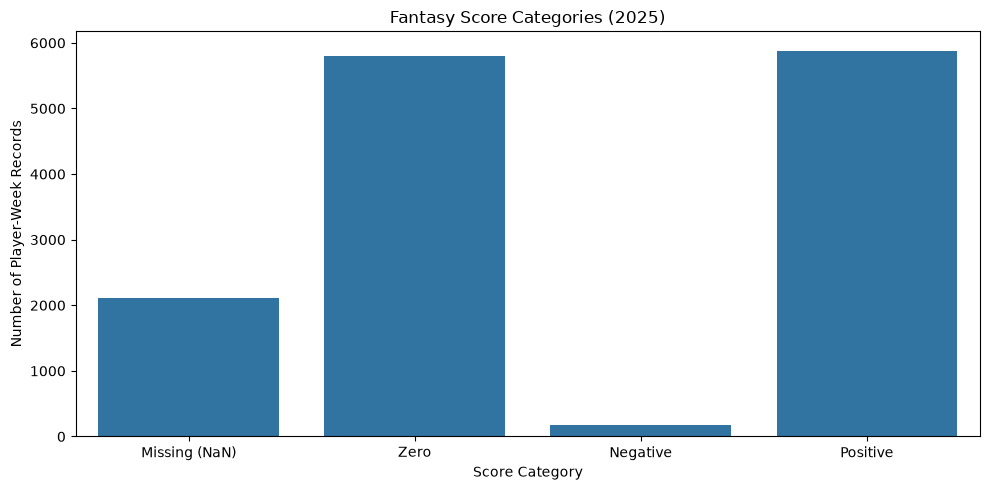

In [8]:
plt.figure(figsize=(10, 5))

order = ["Missing (NaN)", "Zero", "Negative", "Positive"]

sns.countplot(
    data=df,
    x="score_category",
    order=order
)

plt.title("Fantasy Score Categories (2025)")
plt.xlabel("Score Category")
plt.ylabel("Number of Player-Week Records")

plt.tight_layout()
plt.show()

In [9]:
# Count each score category
counts = df["score_category"].value_counts()

# Calculate percentage of total records
percentages = (
    df["score_category"].value_counts(normalize=True) * 100
).round(2)

# Combine into a table
summary = pd.DataFrame({
    "Count": counts,
    "Percentage (%)": percentages
})

display(summary)

,Count,Percentage (%)
score_category,,
Positive,5882,42.14
Zero,5796,41.52
Missing (NaN),2109,15.11
Negative,171,1.23


### Interpretation

The dataset contains 13,958 player-week records from the 2025 NFL season. Approximately 42% of records have positive fantasy scores, while another 41.5% have scores of exactly zero. About 15.1% of records have missing fantasy scores, and only 1.2% have negative scores.

The large proportion of zero scores suggests that many player-week observations have little or no recorded fantasy production. However, we cannot determine whether these players participated in games based on fantasy points alone.

We will retain missing values during EDA and investigate them further before deciding how to handle them during preprocessing.

In [10]:
# Count each score category by position
position_counts = pd.crosstab(
    df["position"],
    df["score_category"]
)

# Calculate percentages within each position
position_percent = (
    position_counts.div(
        position_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

display(position_percent)

score_category,Missing (NaN),Negative,Positive,Zero
position,,,,
9,5.56,0.00,16.67,77.78
D/ST,0.00,15.44,80.33,4.23
K,24.47,0.36,62.11,13.06
QB,8.92,2.52,35.50,53.05
RB,17.35,0.58,41.24,40.84
TE,12.01,0.11,39.09,48.79
WR,17.53,0.39,39.13,42.96


In [12]:
rows_with_9_position = df[df["position"] == "9"]
display(rows_with_9_position)

,player_id,player,position,pro_team_id,week,fantasy_points,projected_points,score_category
436,4373684,Scott Matlock,9,24,1,0.0,0.242357,Zero
1474,4373684,Scott Matlock,9,24,2,0.0,0.245776,Zero
2190,4373684,Scott Matlock,9,24,3,0.0,0.000000,Zero
2917,4373684,Scott Matlock,9,24,4,1.1,0.000000,Positive
3646,4373684,Scott Matlock,9,24,5,0.0,0.265091,Zero
4373,4373684,Scott Matlock,9,24,6,0.0,0.000000,Zero
5109,4373684,Scott Matlock,9,24,7,0.0,0.262617,Zero
5850,4373684,Scott Matlock,9,24,8,0.0,0.000000,Zero
6588,4373684,Scott Matlock,9,24,9,7.2,0.000000,Positive
7340,4373684,Scott Matlock,9,24,10,0.0,0.498915,Zero
